# 02 — Experiments, Ablation, BiLSTM & Error Analysis

This notebook summarizes the classical TF-IDF baselines (Multinomial NB, Logistic Regression, Linear SVM), the Word-Only vs. Word+Char TF-IDF ablation, GridSearchCV tuning, PyTorch BiLSTM training curves, held-out test evaluation, confusion matrices, error analysis, and live post prediction.

In [1]:
import sys
from pathlib import Path

PROJECT_ROOT = Path.cwd().parent if Path.cwd().name == 'notebooks' else Path.cwd()
if str(PROJECT_ROOT) not in sys.path:
    sys.path.insert(0, str(PROJECT_ROOT))

import pandas as pd
from IPython.display import Image, display
from src.evaluate import predict_post
from src.utils import RESULTS_DIR, load_json

# Set to True to re-run the entire pipeline from scratch inside the notebook
RUN_FULL_PIPELINE = False
if RUN_FULL_PIPELINE:
    from main import run_full_pipeline
    run_full_pipeline()


## 1. Model Comparison on Held-Out Test Set

,model,accuracy,macro_precision,macro_recall,macro_f1,weighted_precision,weighted_recall,weighted_f1
0,LinearSVM_Tuned,0.9635,0.9652,0.9648,0.9649,0.9633,0.9635,0.9632
1,LinearSVM,0.9635,0.9652,0.9648,0.9649,0.9633,0.9635,0.9632
2,BiLSTM,0.9624,0.9645,0.9626,0.9635,0.9624,0.9624,0.9623
3,LogisticRegression,0.9598,0.9614,0.9610,0.9611,0.9597,0.9598,0.9597
4,LinearSVM_WordOnly_Ablation,0.9561,0.9590,0.9574,0.9581,0.9560,0.9561,0.9559
5,MultinomialNB,0.8273,0.8734,0.8220,0.8300,0.8656,0.8273,0.8288


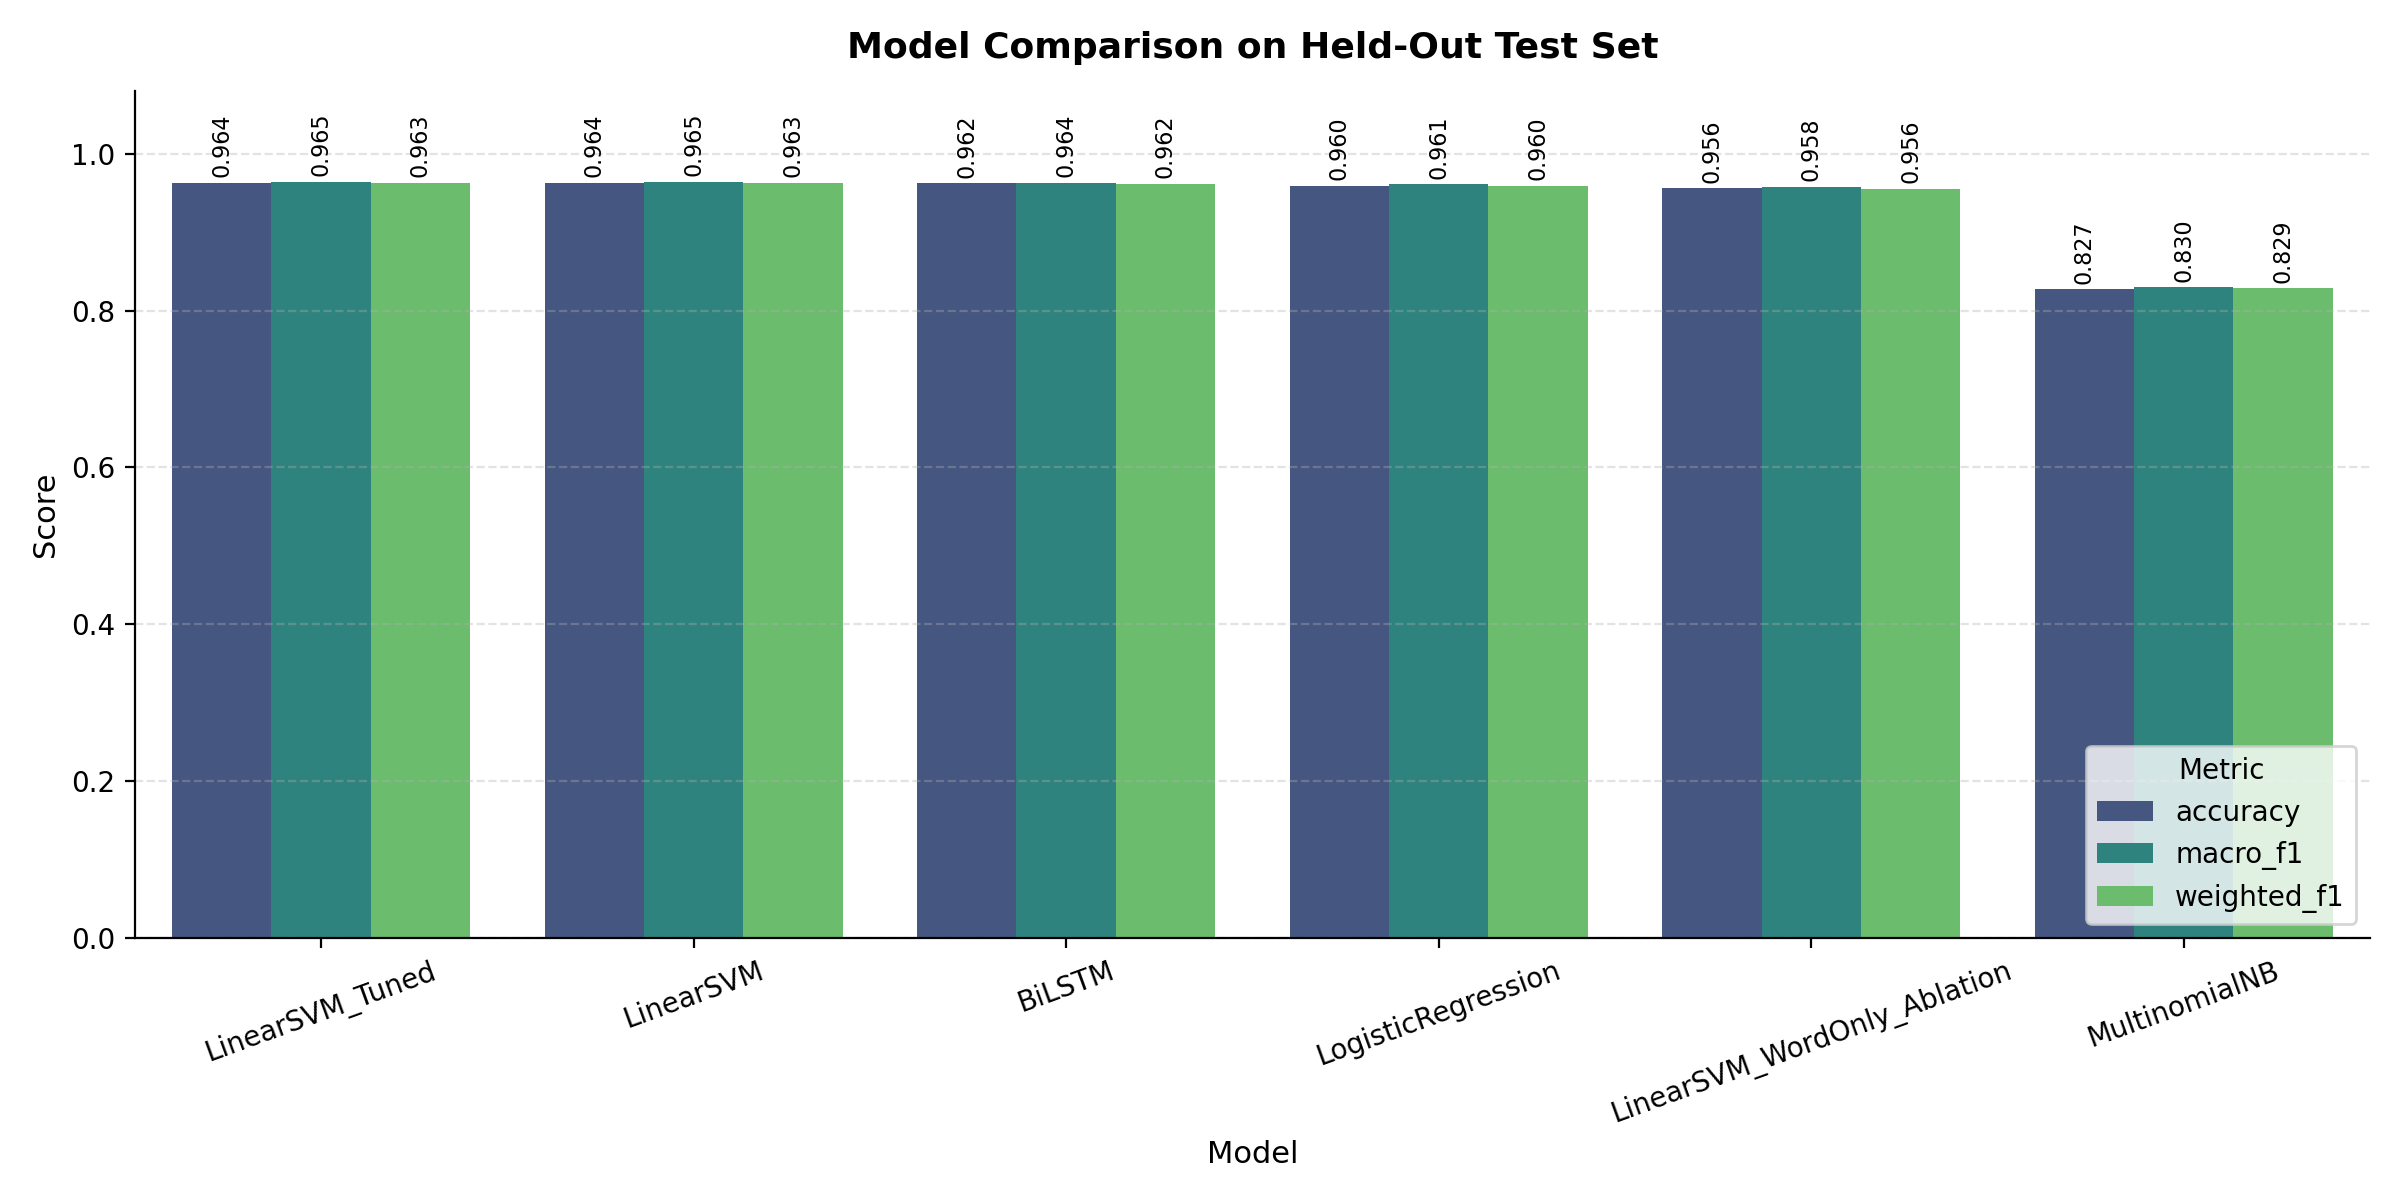

In [2]:
comp_df = pd.read_csv(RESULTS_DIR / 'model_comparison.csv')
display(comp_df)
display(Image(filename=str(RESULTS_DIR / 'model_comparison.png')))

## 2. Classical GridSearchCV & BiLSTM Learning Curves

Best Classical Model: LinearSVM_Tuned
GridSearchCV Best Params: {'C': 1.0}
GridSearchCV Macro-F1: 0.9595


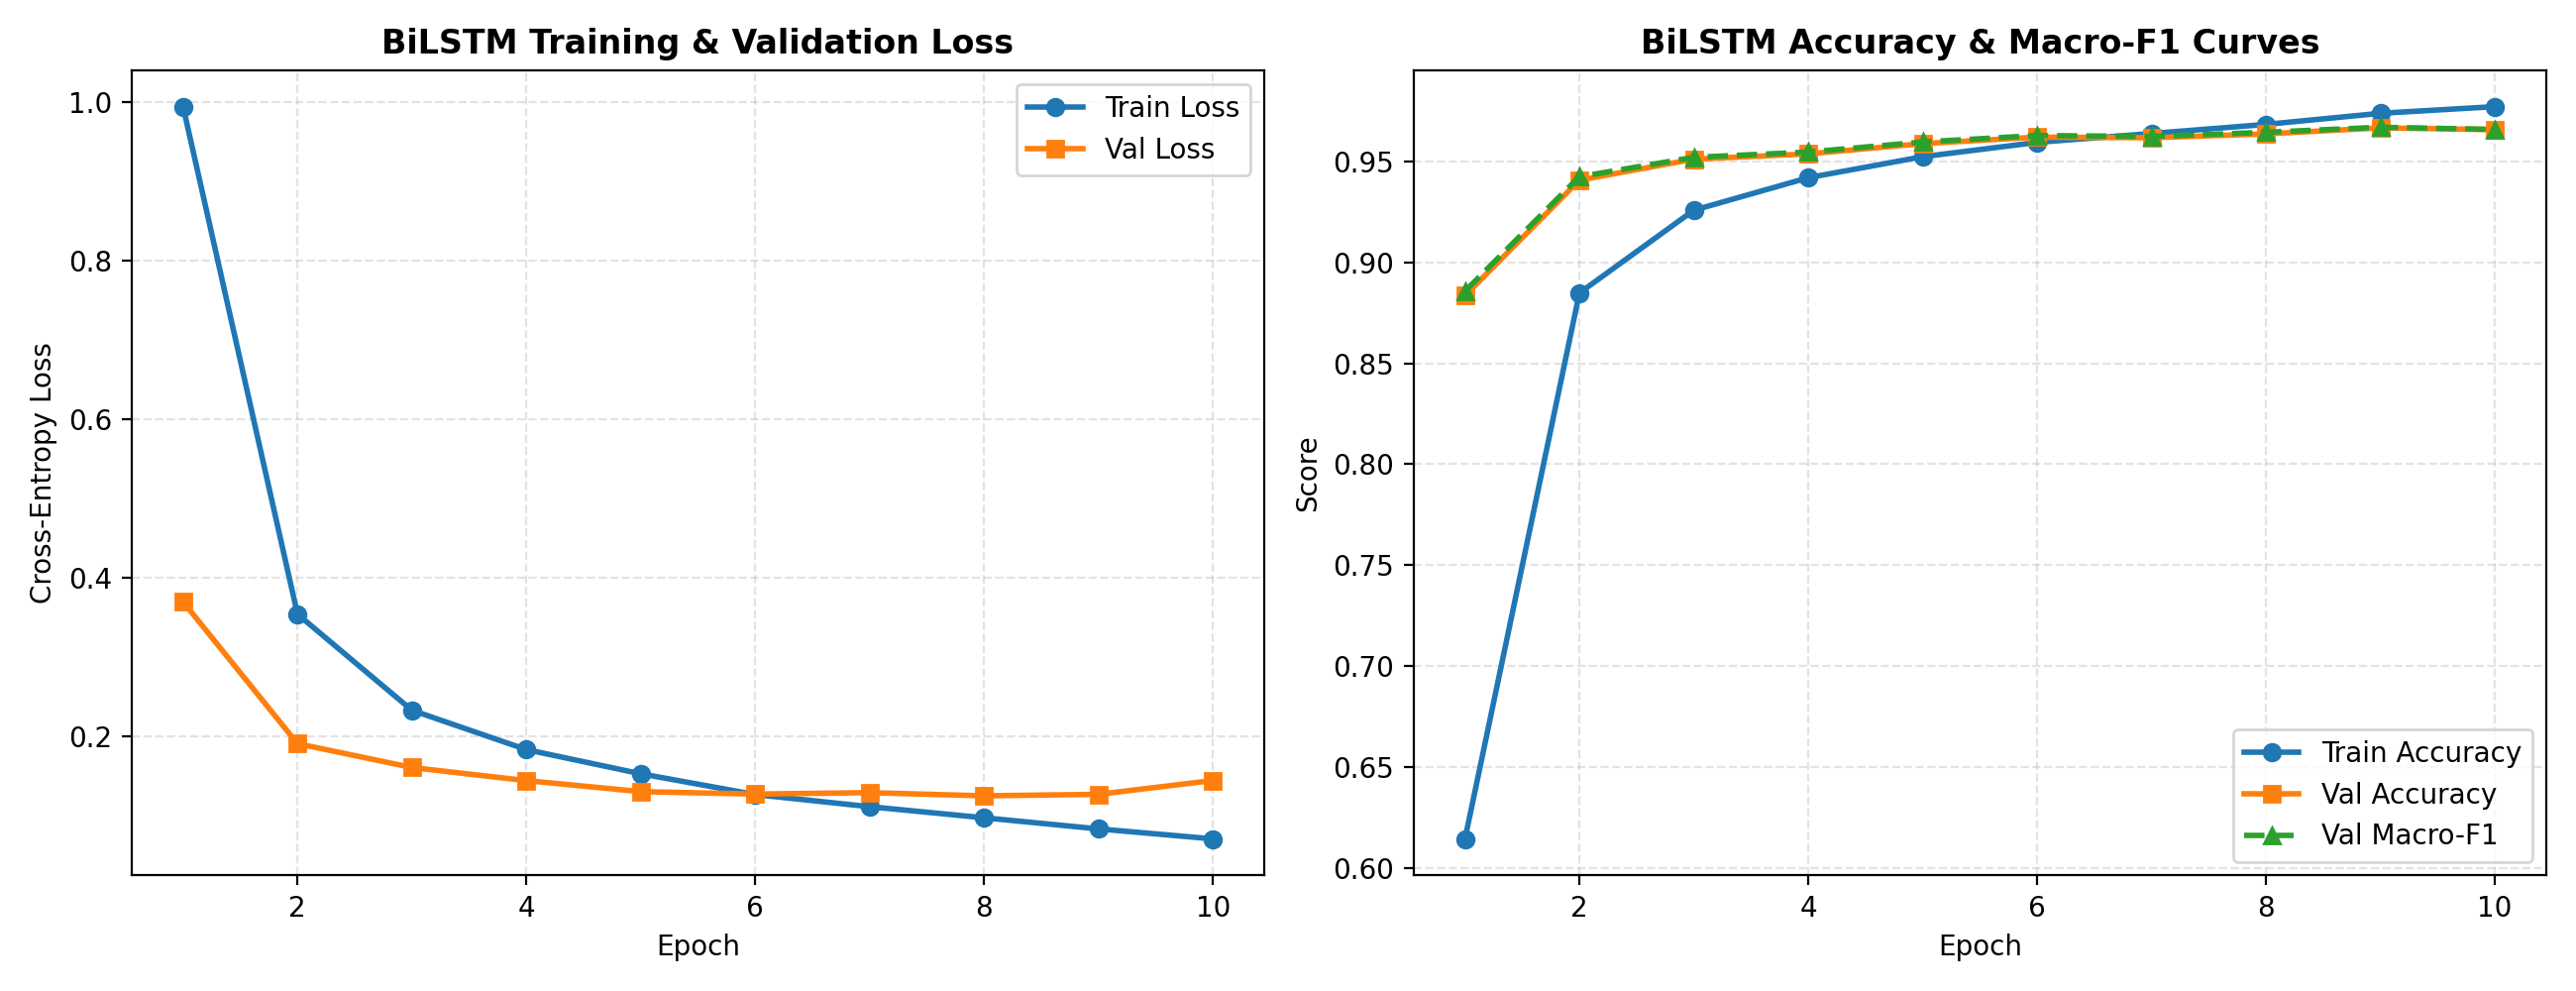

In [3]:
classical_summary = load_json(RESULTS_DIR / 'classical_training_summary.json')
print('Best Classical Model:', classical_summary['tuned_model_name'])
print('GridSearchCV Best Params:', classical_summary['gridsearch_best_params'])
print('GridSearchCV Macro-F1:', classical_summary['gridsearch_cv_macro_f1'])
display(Image(filename=str(RESULTS_DIR / 'bilstm_training_curves.png')))

## 3. Best Model Confusion Matrix (Raw & Normalized)

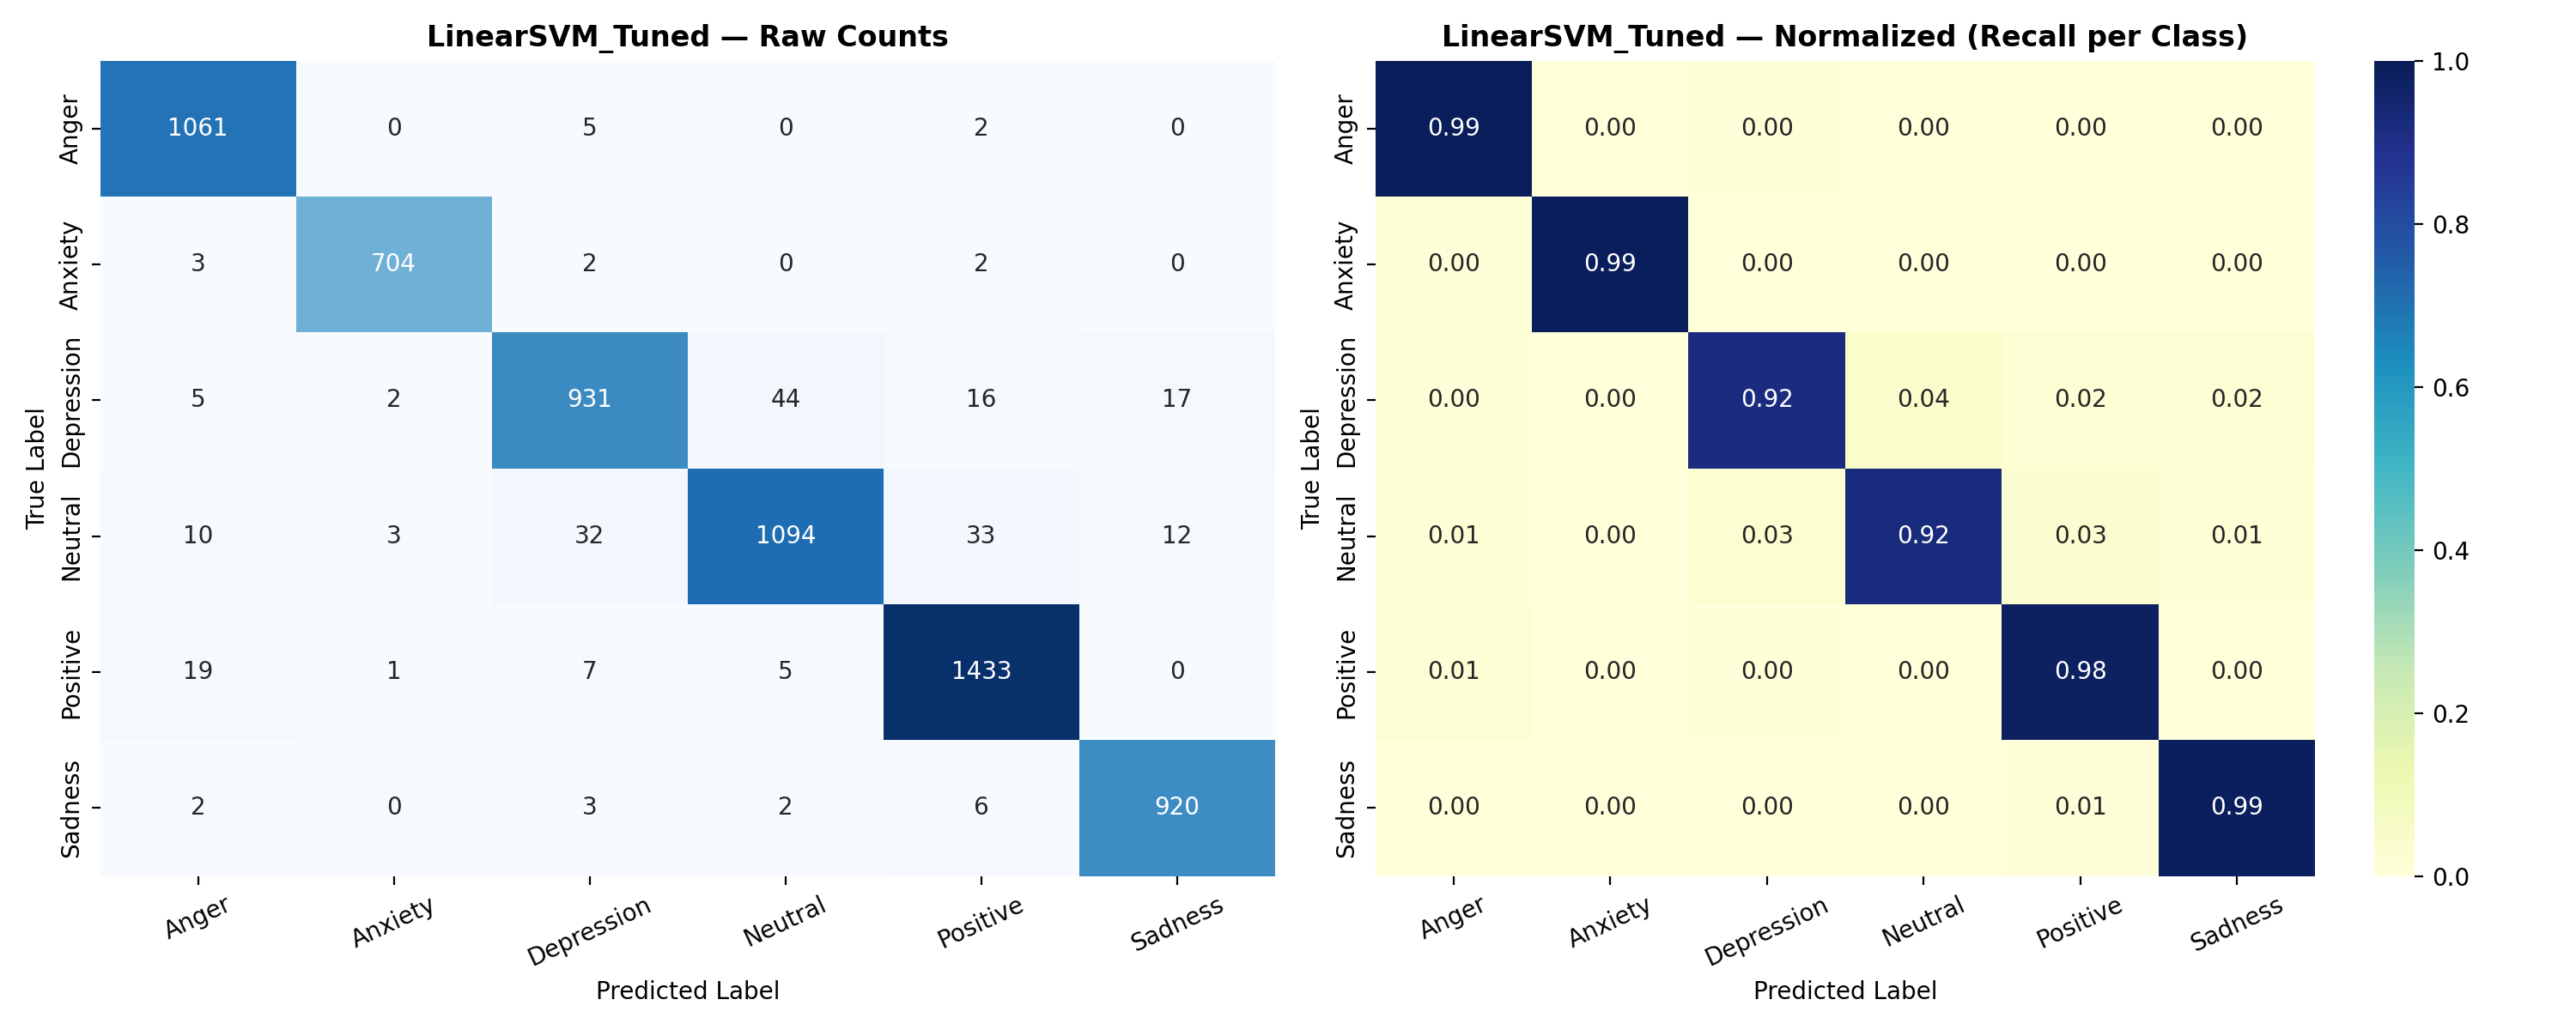

In [4]:
display(Image(filename=str(RESULTS_DIR / 'best_model_confusion_matrix.png')))

## 4. Error Analysis (Misclassified Test Posts)

In [5]:
err_df = pd.read_csv(RESULTS_DIR / 'error_analysis.csv')
err_df[['true_label', 'predicted_label', 'confidence', 'word_count', 'likely_reason', 'raw_text']]

,true_label,predicted_label,confidence,word_count,likely_reason,raw_text
0,Depression,Sadness,0.8679,77,overlapping mental-health/negative affect voca...,I can feel it on my heart. I do not even have ...
1,Neutral,Sadness,0.8547,8,topic/emotion overlap or implicit emotional ex...,is sad that the march break is over
2,Positive,Anger,0.8453,5,very short post (limited context),i feel angry im happy
3,Neutral,Depression,0.8371,106,negation or mixed-sentiment clause,Once I committed mentally to therapy and knew ...
4,Depression,Neutral,0.7901,16,negation or mixed-sentiment clause,"CAN you? did not sink so. You can ban me once,..."
5,Sadness,Anger,0.7731,41,subtle tone or borderline sentiment intensity;...,i feel hated i feel angry i feel very sad i fe...
6,Neutral,Anxiety,0.7184,27,negation or mixed-sentiment clause,Wish to get a surprise in May .Want to be able...
7,Depression,Anger,0.6909,18,topic/emotion overlap or implicit emotional ex...,Want to kill myself because of it. God I hate ...
8,Anger,Depression,0.6865,48,negation or mixed-sentiment clause,im feeling all preasured and all from fueds be...
9,Anger,Positive,0.6639,11,topic/emotion overlap or implicit emotional ex...,i feel defeated unhappy and whatever the oppos...


## 5. Live Inference Demo

In [6]:
demo_posts = [
    'I cant sleep again tonight, my chest feels tight and im panicking #anxiety',
    'Everything feels pointless lately, I just want to stay in bed all day.',
    'Just finished my final lab experiment!! So grateful for my team 😊 #proud',
    'Why did they cancel the train without telling anyone?! So infuriating!!',
]
pd.DataFrame([predict_post(p) for p in demo_posts])[['raw_text', 'predicted_label', 'confidence', 'model_used']]

,raw_text,predicted_label,confidence,model_used
0,"I cant sleep again tonight, my chest feels tig...",Anxiety,0.6497,LinearSVM_Tuned
1,"Everything feels pointless lately, I just want...",Depression,0.3085,LinearSVM_Tuned
2,Just finished my final lab experiment!! So gra...,Neutral,0.3377,LinearSVM_Tuned
3,Why did they cancel the train without telling ...,Neutral,0.3925,LinearSVM_Tuned
